In [4]:
%pip install numpy matplotlib scipy sympy vpython

Note: you may need to restart the kernel to use updated packages.


## Q1. Find and visualize the minimum of f(x) = x² − 4x + 5

- **SciPy (`minimize_scalar`)** finds the numerical minimum.
- **NumPy (`linspace`)** generates x-values for plotting.
- **Matplotlib** draws the function and marks the minimum.

The minimum is at x = 2, where f(x) = 1.

Exception ignored in: <function standardAttributes.__del__ at 0x10c6b47c0>
Traceback (most recent call last):
  File "/Users/ankitkumar/.local/share/uv/python/cpython-3.12.13-macos-aarch64-none/lib/python3.12/site-packages/vpython/vpython.py", line 1176, in __del__
    super(standardAttributes, self).__del__()
  File "/Users/ankitkumar/.local/share/uv/python/cpython-3.12.13-macos-aarch64-none/lib/python3.12/site-packages/vpython/vpython.py", line 348, in __del__
    cmd = {"cmd": "delete", "idx": self.idx}
                                   ^^^^^^^^
AttributeError: 'sphere' object has no attribute 'idx'


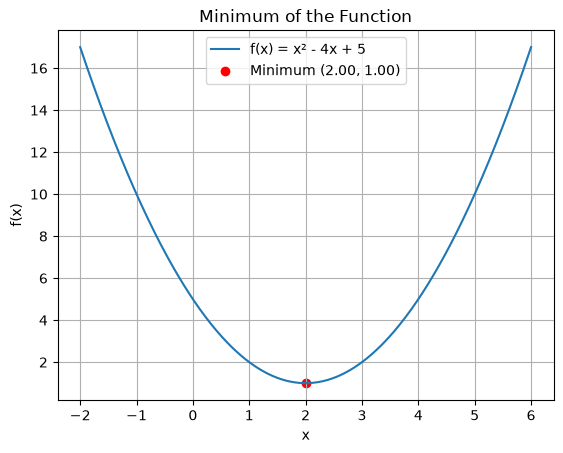

Minimum x = 2.0
Minimum value = 1.0


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

def f(x):
    return x**2 - 4*x + 5

# (a) Find the minimum numerically using SciPy
result = minimize_scalar(f, bounds=(-10, 10), method="bounded")
x_min = result.x
y_min = result.fun

# (b) Generate values of x using NumPy
x = np.linspace(-2, 6, 400)
y = f(x)

# (c) Visualize using Matplotlib
plt.plot(x, y, label="f(x) = x² - 4x + 5")
plt.scatter(x_min, y_min, color="red", label=f"Minimum ({x_min:.2f}, {y_min:.2f})")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Minimum of the Function")
plt.grid(True)
plt.legend()
plt.show()

print("Minimum x =", x_min)
print("Minimum value =", y_min)

## Q2. Monthly electricity bill using user-defined functions

In [6]:
def calculate_energy_charge(units):
    if units < 0:
        raise ValueError("Units consumed cannot be negative.")

    if units <= 100:
        charge = units * 5
    elif units <= 200:
        charge = 100 * 5 + (units - 100) * 7
    else:
        charge = 100 * 5 + 100 * 7 + (units - 200) * 10

    return charge

def calculate_tax(energy_charge):
    return energy_charge * 0.05

def display_bill(units):
    energy_charge = calculate_energy_charge(units)
    tax = calculate_tax(energy_charge)
    total_bill = energy_charge + tax

    print("Units consumed:", units)
    print(f"Energy charge: Rs. {energy_charge:.2f}")
    print(f"Tax (5%): Rs. {tax:.2f}")
    print(f"Total bill: Rs. {total_bill:.2f}")

units = float(input("Enter units consumed: "))
display_bill(units)

Units consumed: 120.0
Energy charge: Rs. 640.00
Tax (5%): Rs. 32.00
Total bill: Rs. 672.00


## Q3. Sensor temperature analysis using dictionaries, `map()` and lambda

In [7]:
sensor_data = {
    "S01": [23.5, 25.2, 27.1, 29.8],
    "S02": [21.4, 24.8, 26.3, 25.7],
    "S03": [30.2, 31.5, 29.9, 32.1]
}

# Calculate the average temperature of each sensor
average_temperatures = {}
for sensor, temperatures in sensor_data.items():
    average_temperatures[sensor] = sum(temperatures) / len(temperatures)

print("Average temperatures:")
for sensor, average in average_temperatures.items():
    print(sensor, ":", round(average, 2), "°C")

# Find the sensor with the highest average temperature
highest_sensor = max(average_temperatures, key=average_temperatures.get)
print("\nHighest average temperature:", highest_sensor)
print("Average:", round(average_temperatures[highest_sensor], 2), "°C")

# Convert Celsius to Fahrenheit using map() and lambda
fahrenheit_data = {}
for sensor, temperatures in sensor_data.items():
    fahrenheit_data[sensor] = list(map(lambda c: (c * 9/5) + 32, temperatures))

print("\nTemperatures in Fahrenheit:")
for sensor, temperatures in fahrenheit_data.items():
    print(sensor, ":", [round(t, 2) for t in temperatures])

Average temperatures:
S01 : 26.4 °C
S02 : 24.55 °C
S03 : 30.93 °C

Highest average temperature: S03
Average: 30.93 °C

Temperatures in Fahrenheit:
S01 : [74.3, 77.36, 80.78, 85.64]
S02 : [70.52, 76.64, 79.34, 78.26]
S03 : [86.36, 88.7, 85.82, 89.78]


## Q4. Object-oriented banking application

`BankAccount` is the base class. The balance is encapsulated using a private attribute (`__balance`) and accessed through a read-only property. `SavingsAccount` inherits from it and overrides `add_interest()` to add interest to the balance.

In [8]:
class BankAccount:
    def __init__(self, account_number, account_holder, balance):
        if balance < 0:
            raise ValueError("Opening balance cannot be negative.")
        self.accountNumber = account_number
        self.accountHolder = account_holder
        self.__balance = balance  # Private attribute

    @property
    def balance(self):
        return self.__balance

    def Deposit(self, amount):
        if amount <= 0:
            print("Invalid deposit amount.")
            return
        self.__balance += amount
        print(f"Rs. {amount:.2f} deposited successfully.")

    def withdraw(self, amount):
        if amount <= 0:
            print("Invalid withdrawal amount.")
        elif amount > self.__balance:
            print("Insufficient balance.")
        else:
            self.__balance -= amount
            print(f"Rs. {amount:.2f} withdrawn successfully.")

    def display_account_details(self):
        print("Account number:", self.accountNumber)
        print("Account holder:", self.accountHolder)
        print(f"Balance: Rs. {self.balance:.2f}")

    def add_interest(self):
        # Base account does not earn interest
        pass


class SavingsAccount(BankAccount):
    def __init__(self, account_number, account_holder, balance, interest_rate):
        super().__init__(account_number, account_holder, balance)
        self.interest_rate = interest_rate

    def add_interest(self):
        interest = self.balance * self.interest_rate / 100
        self.Deposit(interest)
        print(f"Interest added: Rs. {interest:.2f}")


# Create multiple account objects and store them in a list
accounts = [
    BankAccount("A101", "Rahul", 5000),
    SavingsAccount("S201", "Priya", 10000, 5),
    SavingsAccount("S202", "Aman", 8000, 4)
]

accounts[0].Deposit(1000)
accounts[0].withdraw(500)
accounts[1].add_interest()

print("\nAccount details:")
for account in accounts:
    account.display_account_details()
    print()

# Map each account type to a set of account numbers
account_types = {}
for account in accounts:
    account_type = type(account).__name__
    if account_type not in account_types:
        account_types[account_type] = set()
    account_types[account_type].add(account.accountNumber)

print("Account type mapping:", account_types)

Rs. 1000.00 deposited successfully.
Rs. 500.00 withdrawn successfully.
Rs. 500.00 deposited successfully.
Interest added: Rs. 500.00

Account details:
Account number: A101
Account holder: Rahul
Balance: Rs. 5500.00

Account number: S201
Account holder: Priya
Balance: Rs. 10500.00

Account number: S202
Account holder: Aman
Balance: Rs. 8000.00

Account type mapping: {'BankAccount': {'A101'}, 'SavingsAccount': {'S201', 'S202'}}


## Q5. Grayscale image operations using NumPy

In [9]:
import numpy as np

# Create a 6x6 grayscale image matrix (pixel values from 0 to 255)
image = np.array([
    [10,  40,  80, 120, 160, 200],
    [20,  60, 100, 140, 180, 220],
    [30,  70, 110, 150, 190, 230],
    [40,  80, 120, 160, 200, 240],
    [50,  90, 130, 170, 210, 250],
    [60, 100, 140, 180, 220, 255]
], dtype=np.uint8)

print("Original image matrix:\n", image)

# Convert to binary image using threshold 128
binary_image = (image >= 128).astype(int)
print("\nBinary image (threshold = 128):\n", binary_image)

# Find maximum, minimum and average intensity
print("\nMaximum intensity:", image.max())
print("Minimum intensity:", image.min())
print("Average intensity:", image.mean())

# Extract central 4x4 portion
central_4x4 = image[1:5, 1:5]
print("\nCentral 4x4 portion:\n", central_4x4)

# Increase brightness by 30 and limit values to 255
bright_image = np.clip(image.astype(int) + 30, 0, 255).astype(np.uint8)
print("\nImage after increasing brightness by 30:\n", bright_image)

Original image matrix:
 [[ 10  40  80 120 160 200]
 [ 20  60 100 140 180 220]
 [ 30  70 110 150 190 230]
 [ 40  80 120 160 200 240]
 [ 50  90 130 170 210 250]
 [ 60 100 140 180 220 255]]

Binary image (threshold = 128):
 [[0 0 0 0 1 1]
 [0 0 0 1 1 1]
 [0 0 0 1 1 1]
 [0 0 0 1 1 1]
 [0 0 1 1 1 1]
 [0 0 1 1 1 1]]

Maximum intensity: 255
Minimum intensity: 10
Average intensity: 133.47222222222223

Central 4x4 portion:
 [[ 60 100 140 180]
 [ 70 110 150 190]
 [ 80 120 160 200]
 [ 90 130 170 210]]

Image after increasing brightness by 30:
 [[ 40  70 110 150 190 230]
 [ 50  90 130 170 210 250]
 [ 60 100 140 180 220 255]
 [ 70 110 150 190 230 255]
 [ 80 120 160 200 240 255]
 [ 90 130 170 210 250 255]]


## Q6. Torque, work and angle using NumPy

The torque vector is the cross product \(\tau = r \times F\). Work is the dot product \(W = F \cdot d\). The angle is found from the dot-product formula.

In [10]:
import numpy as np

F = np.array([10, 20, 30], dtype=float)  # Force in N
r = np.array([2, 3, 1], dtype=float)     # Position in m
d = np.array([3, 1, 2], dtype=float)     # Displacement in m

# (i) Torque magnitude
torque = np.cross(r, F)
torque_magnitude = np.linalg.norm(torque)
print("Torque vector:", torque, "N m")
print("Magnitude of torque:", torque_magnitude, "N m")

# (ii) Work done
work = np.dot(F, d)
print("Work done:", work, "J")

# (iii) Angle between force and displacement
cos_theta = np.dot(F, d) / (np.linalg.norm(F) * np.linalg.norm(d))
cos_theta = np.clip(cos_theta, -1.0, 1.0)  # Avoid rounding errors
angle_degrees = np.degrees(np.arccos(cos_theta))
print("Angle between F and d:", angle_degrees, "degrees")

# (iv) Physical meaning:
# Dot product gives a scalar and measures the component of one vector
# along another; here it gives work done by the force.
# Cross product gives a vector perpendicular to the two input vectors;
# here it gives torque, which measures the turning effect of the force.

Torque vector: [ 70. -50.  10.] N m
Magnitude of torque: 86.60254037844386 N m
Work done: 110.0 J
Angle between F and d: 38.21321070173819 degrees


## Q7. Inset Axes using Matplotlib `add_axes()`

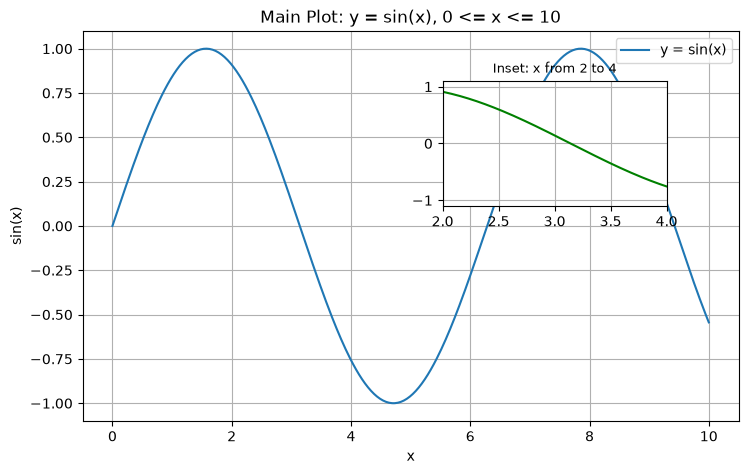

In [11]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 10, 400)
y = np.sin(x)

fig = plt.figure(figsize=(8, 5))

# Main Axes
main_ax = fig.add_axes([0.10, 0.12, 0.82, 0.78])
main_ax.plot(x, y, label="y = sin(x)")
main_ax.set_xlabel("x")
main_ax.set_ylabel("sin(x)")
main_ax.set_title("Main Plot: y = sin(x), 0 <= x <= 10")
main_ax.grid(True)
main_ax.legend()

# Inset Axes placed inside the main Axes
inset_ax = fig.add_axes([0.55, 0.55, 0.28, 0.25])
inset_ax.plot(x, y, color="green")
inset_ax.set_xlim(2, 4)
inset_ax.set_title("Inset: x from 2 to 4", fontsize=9)
inset_ax.grid(True)

plt.show()

## Q8. Velocity, acceleration and displacement using SymPy

Velocity is the first derivative of displacement, and acceleration is the second derivative. The velocity is zero at the stationary instants.

In [12]:
import sympy as sp

t = sp.symbols("t")
s = t**3 - 6*t**2 + 9*t + 4

# Differentiate displacement
velocity = sp.diff(s, t)
acceleration = sp.diff(velocity, t)

print("Displacement s(t) =", s)
print("Velocity v(t) =", velocity)
print("Acceleration a(t) =", acceleration)

# Solve v(t) = 0
stationary_times = sp.solve(sp.Eq(velocity, 0), t)
print("\nTime when velocity is zero:", stationary_times)

# Find displacement at those time instants
for time in stationary_times:
    displacement = s.subs(t, time)
    print(f"Displacement at t = {time}: {displacement}")

Displacement s(t) = t**3 - 6*t**2 + 9*t + 4
Velocity v(t) = 3*t**2 - 12*t + 9
Acceleration a(t) = 6*t - 12

Time when velocity is zero: [1, 3]
Displacement at t = 1: 8
Displacement at t = 3: 4


## Q9. Definite integration using SciPy

Use `scipy.integrate.quad()` to estimate the integral and its absolute error.

In [13]:
import numpy as np
from scipy.integrate import quad

def f(x):
    return np.exp(-x**2)

estimated_result, estimated_absolute_error = quad(f, 0, 1)

print("Estimated integral:", estimated_result)
print("Estimated absolute error:", estimated_absolute_error)

Estimated integral: 0.7468241328124271
Estimated absolute error: 8.291413475940725e-15


## Q10. Ball falling under gravity using VPython

The ball starts above a flat floor. Gravity changes its vertical velocity, and its position is updated inside a `while` loop. When it touches the floor, its vertical velocity is reversed to make it bounce.

Run this cell in a Python environment where VPython is installed and its 3D display is supported.

In [14]:
%pip install "setuptools<81"

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from vpython import canvas, sphere, box, vector, color, rate

scene = canvas(width=700, height=450)

floor = box(pos=vector(0, 0, 0), size=vector(10, 0.2, 10), color=color.green)
ball = sphere(pos=vector(0, 5, 0), radius=0.5, color=color.red)

g = -9.8
v = vector(0, 0, 0)
dt = 0.01
t = 0

while t < 20:
    rate(60)

    v.y = v.y + g * dt
    ball.pos = ball.pos + v * dt

    # floor se takrane par velocity reverse
    if ball.pos.y - ball.radius <= floor.pos.y + floor.size.y / 2:
        ball.pos.y = floor.pos.y + floor.size.y / 2 + ball.radius
        v.y = -v.y

    t = t + dt

print("Done")

In [17]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

g = -9.8
dt = 0.02
radius = 0.5
floor_y = 0.0

ys = []
y, vy = 5.0, 0.0
for _ in range(400):
    vy += g * dt
    y += vy * dt
    if y - radius <= floor_y:
        y = floor_y + radius
        vy = -vy
    ys.append(y)

fig, ax = plt.subplots(figsize=(4, 6))
ax.set_xlim(-3, 3)
ax.set_ylim(-0.5, 6)
ax.set_aspect("equal")
ax.axhspan(-0.5, floor_y, color="green")
ball = plt.Circle((0, ys[0]), radius, color="red")
ax.add_patch(ball)

def update(i):
    ball.center = (0, ys[i])
    return (ball,)

ani = FuncAnimation(fig, update, frames=len(ys), interval=20)
plt.close(fig)
HTML(ani.to_jshtml())